# 03 · Q2 — Seller tiers with K-means

**Question (Q2):** Which sellers should managers prioritize, based on the **severity** (late handover
rate) and **scale** (number of late handovers) of late carrier handovers?

**Input:** `Data/Clean/seller_metrics.csv` and `Data/Clean/orders_main.csv` from `01_cleaning.ipynb`
(main sample of 93,598 orders, January 2017 – August 2018, lateness measured by calendar date).

**Steps:** keep sellers with enough orders → K-means on two lateness features → choose k → profile
each tier → describe each tier's customer ratings → pick the focus tiers with a lateness rule → rank
the sellers inside the focus tiers → save. Robustness checks are in `04_checks.ipynb`.

**How to read the result.** The two features measure the same thing from two sides, so K-means cuts
sellers into ordered **tiers on one lateness scale**. It does not find separate types of sellers
(Section 3 shows this). Ratings only describe the tiers; they do not decide anything.

Shared functions (building tiers, profiles, focus tiers) are in `notebooks/q2_tiers.py`, so that
`04_checks` reruns exactly the same steps.

## 0. Settings

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import adjusted_rand_score, silhouette_score

from q2_tiers import add_excess, assign_tiers, fit_kmeans, focus_tiers, make_features, profile_tiers

SELLER_METRICS_PATH = "../Data/Clean/seller_metrics.csv"
ORDERS_PATH = "../Data/Clean/orders_main.csv"
RESULTS_DIR = "../Data/Results"   # outputs of the analysis notebooks
FIG_DIR = "../figures"            # figures are named by question and item number, as in Q1
MIN_ORDERS = 20                   # main analysis; 10 and 30 are tested in 04_checks
K_RANGE = range(2, 9)             # numbers of tiers to compare
CHOSEN_K = 4                      # see Section 3
RANDOM_STATE = 42                 # fixed seed so every run gives the same result
RATING_COL = "review_score_last"  # latest review per order; review_score_first is compared in 04_checks
LOW_RATING = 2                    # a review of 2 stars or less counts as a low rating
# Tier names used on the charts, slides and report; they describe the k = 4 profile in Section 4
TIER_NAMES = {1: "Rarely late", 2: "Occasionally late", 3: "Slightly above platform, high volume", 4: "Severely late"}

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Shared chart style: thin marks, light grid, no top/right frame
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
})
# Tiers are ordered, so they use one blue hue from light (least late) to dark (most late)
TIER_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b", "#0a2a52", "#071f3d", "#05172d", "#030f1e"]
TIER_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]

## 1. Load the seller table and apply the minimum-order threshold

The threshold is applied **only to the clustering**. No orders are deleted: the platform late rate and
the monthly benchmark still use all 93,598 orders. Sellers with very few orders have unreliable late
rates (one late order out of two is already 50%).

In [2]:
sellers_all = pd.read_csv(SELLER_METRICS_PATH)
platform_late_rate = sellers_all["late_orders"].sum() / sellers_all["order_volume"].sum()

eligible = sellers_all[sellers_all["order_volume"] >= MIN_ORDERS].reset_index(drop=True)
order_share = eligible["order_volume"].sum() / sellers_all["order_volume"].sum()

print(f"Platform late rate (all {sellers_all['order_volume'].sum():,} orders): {platform_late_rate:.2%}")
print(f"Sellers: {len(sellers_all):,} in total, {len(eligible):,} with at least {MIN_ORDERS} orders")
print(f"These sellers cover {order_share:.1%} of orders")

Platform late rate (all 93,598 orders): 5.78%
Sellers: 2,917 in total, 778 with at least 20 orders
These sellers cover 87.5% of orders


## 2. Features for clustering

| Feature | Part of Q2 | Why this form |
|---|---|---|
| `late_rate` | severity: share of a seller's orders handed over late | already between 0 and 1 |
| log(1 + `late_orders`) | scale: number of late handovers | late orders run from 0 to almost 200, so the log stops a few sellers from dominating; the "+1" handles the third of sellers with no late orders, because log(0) is undefined |

**Why late orders and not order volume.** Q2 asks about the scale of *late handovers*, not the size of
the seller. With order volume as the second feature (the earlier version), the seller with the most late
handovers (963 orders, 189 late) was grouped with large sellers that are mostly on time. That comparison
is rerun in `04_checks`.

Both features are standardized (mean 0, standard deviation 1) so that K-means weighs them equally.

In [3]:
X = make_features(eligible)
print("Feature matrix shape:", X.shape)
print(f"Sellers with no late orders: {(eligible['late_orders'] == 0).mean():.0%}")
print(f"Correlation between the two features: {np.corrcoef(X[:, 0], X[:, 1])[0, 1]:.2f}")

Feature matrix shape: (778, 2)
Sellers with no late orders: 32%
Correlation between the two features: 0.68


## 3. Choosing k — and what the silhouette score can and cannot show

K-means always returns k groups and a silhouette score, even when the data has no groups. So each score is
compared with a **baseline with no groups by construction**: every seller keeps its own order volume but
gets the late rate of a randomly chosen other seller, and its late orders are rebuilt from the two. This
keeps the built-in link between late rate and late orders but removes any real grouping of sellers.

In [4]:
def baseline_silhouette(eligible, k, rng):
    """Silhouette for sellers whose late rates were randomly reassigned (no real groups)."""
    volume = eligible["order_volume"].to_numpy()
    late = np.round(rng.permutation(eligible["late_rate"].to_numpy()) * volume)
    fake = pd.DataFrame({"late_rate": late / volume, "late_orders": late})
    Z = make_features(fake)
    return silhouette_score(Z, fit_kmeans(Z, k).labels_)


rng = np.random.default_rng(RANDOM_STATE)
k_rows = []
for k in K_RANGE:
    model = fit_kmeans(X, k)
    k_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X, model.labels_),
        "baseline_no_groups": np.mean([baseline_silhouette(eligible, k, rng) for _ in range(10)]),
    })
k_table = pd.DataFrame(k_rows)
k_table.round(3)

,k,inertia,silhouette,baseline_no_groups
0,2,694.835,0.583,0.601
1,3,412.607,0.553,0.583
2,4,291.715,0.535,0.588
3,5,222.274,0.538,0.614
4,6,171.797,0.587,0.627
5,7,138.643,0.596,0.629
6,8,118.280,0.593,0.630


**What this shows.** The real silhouette score is **not higher** than the no-groups baseline for any k.
So the sellers do not form natural groups: they lie along one lateness scale, and K-means cuts that scale
into ordered tiers. The elbow has no sharp bend either, so neither method picks k.

**Choice of k = 4** is a judgement for interpretation: four tiers (rarely late, occasionally late,
slightly above the platform with high volume, severely late) can each be given a management action. Other values of k are compared in
`04_checks`.

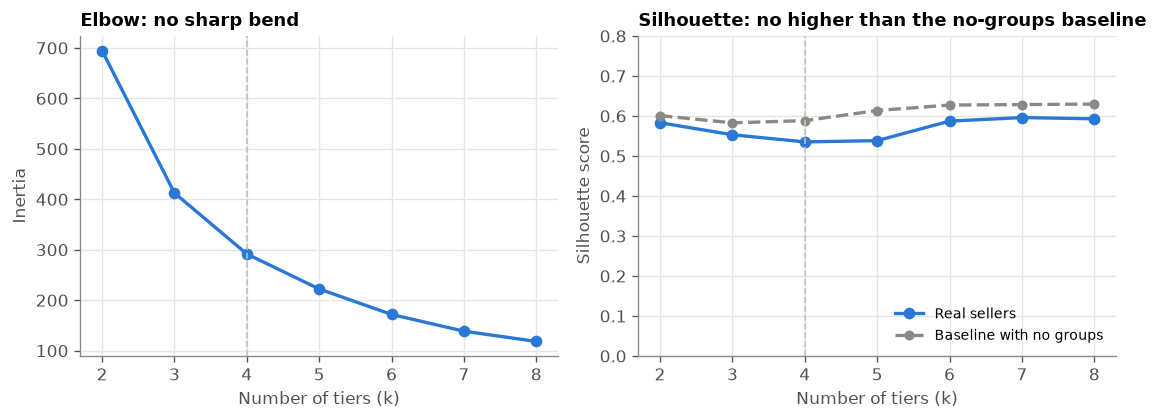

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.6))
ax1.plot(k_table["k"], k_table["inertia"], color="#2a78d6", linewidth=2, marker="o", markersize=6)
ax1.set_title("Elbow: no sharp bend", loc="left")
ax1.set_ylabel("Inertia")

ax2.plot(k_table["k"], k_table["silhouette"], color="#2a78d6", linewidth=2, marker="o", markersize=6,
         label="Real sellers")
ax2.plot(k_table["k"], k_table["baseline_no_groups"], color="#8a8984", linestyle="--", linewidth=2,
         marker="o", markersize=5, label="Baseline with no groups")
ax2.set_title("Silhouette: no higher than the no-groups baseline", loc="left")
ax2.set_ylabel("Silhouette score")
ax2.set_ylim(0, 0.8)
ax2.legend(frameon=False, fontsize=8.5, loc="lower right")

for ax in (ax1, ax2):
    ax.axvline(CHOSEN_K, color="#c3c2b7", linestyle="--", linewidth=1)
    ax.set_xlabel("Number of tiers (k)")
    ax.set_xticks(list(K_RANGE))
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/q2_01_choose_k.png", bbox_inches="tight")
plt.show()

## 4. Final tiers and their profiles

Tiers are numbered **1 to k from the lowest to the highest average late rate**.
`gap_vs_same_month_pp` compares each tier's late handovers with what the same-month platform rate would
predict for the months its sellers sold in. A positive gap means the tier is late more often than the
platform was in the same months.

In [6]:
sellers = add_excess(assign_tiers(sellers_all, CHOSEN_K, MIN_ORDERS))
profile = profile_tiers(sellers)
profile.style.format({
    "median_orders": "{:.0f}",
    "median_late_orders": "{:.0f}",
    "late_rate": "{:.1%}",
    "gap_vs_same_month_pp": "{:+.1f}",
    "share_of_sellers": "{:.0%}",
    "share_of_orders": "{:.0%}",
    "share_of_late_orders": "{:.0%}",
})

,sellers,median_orders,median_late_orders,total_orders,late_orders,late_rate,gap_vs_same_month_pp,share_of_sellers,share_of_orders,share_of_late_orders
tier,,,,,,,,,,
1,383,37,0,20756,132,0.6%,-5.1,49%,25%,3%
2,236,64,3,28457,907,3.2%,-2.6,30%,35%,20%
3,132,101,13,30406,2623,8.6%,+2.8,17%,37%,58%
4,27,63,27,2302,831,36.1%,+29.9,3%,3%,18%


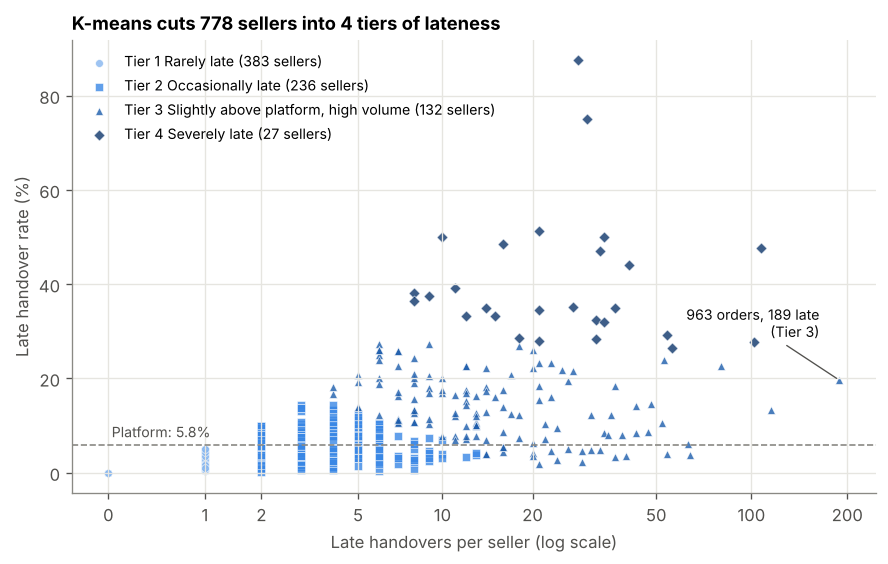

In [7]:
# Plot in the same two dimensions K-means used: late orders (log scale) and late rate
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for t in range(1, CHOSEN_K + 1):
    group = sellers[sellers["tier"] == t]
    ax.scatter(
        group["late_orders"] + 1, group["late_rate"] * 100,
        s=22, alpha=0.8, color=TIER_COLORS[t - 1], marker=TIER_MARKERS[t - 1],
        edgecolors="white", linewidths=0.4, label=f"Tier {t} {TIER_NAMES.get(t, '')} ({len(group)} sellers)",
    )

# Point out the seller with the most late handovers
top = sellers.loc[sellers["late_orders"].idxmax()]
ax.annotate(
    f"{int(top['order_volume'])} orders, {int(top['late_orders'])} late\n(Tier {int(top['tier'])})",
    (top["late_orders"] + 1, top["late_rate"] * 100), xytext=(-12, 26), textcoords="offset points",
    ha="right", fontsize=8.5, color="#0b0b0b", arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.8),
)

ax.axhline(platform_late_rate * 100, color="#8a8984", linestyle="--", linewidth=1)
ax.annotate(f"Platform: {platform_late_rate:.1%}", (1, platform_late_rate * 100), xytext=(2, 5),
            textcoords="offset points", fontsize=8.5, color="#52514e")
ax.set_xscale("log")
ticks = [0, 1, 2, 5, 10, 20, 50, 100, 200]
ax.set_xticks([t + 1 for t in ticks])
ax.set_xticklabels([str(t) for t in ticks])
ax.minorticks_off()
ax.set_xlabel("Late handovers per seller (log scale)")
ax.set_ylabel("Late handover rate (%)")
ax.set_title(f"K-means cuts {len(sellers)} sellers into {CHOSEN_K} tiers of lateness", loc="left")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/q2_02_tiers.png", bbox_inches="tight")
plt.show()

In [8]:
# Quick stability check: refit with 10 other seeds; 1 = identical tiers
ari_scores = [
    adjusted_rand_score(fit_kmeans(X, CHOSEN_K).labels_, fit_kmeans(X, CHOSEN_K, random_state=seed).labels_)
    for seed in range(10)
]
print(f"Adjusted Rand index across 10 seeds: min {min(ari_scores):.3f}, mean {np.mean(ari_scores):.3f}")

Adjusted Rand index across 10 seeds: min 0.980, mean 0.994


## 5. Customer ratings by tier (description only)

Ratings are **not** a clustering feature and do not decide the focus tiers. Two cautions:

- **Built-in link.** Tiers are defined by lateness and late orders get lower ratings, so higher tiers are
  expected to score lower. The second table below looks only at orders that were on time at both steps.
- **Association, not cause.** Ratings also depend on carrier delivery and product quality. `04_checks`
  adjusts the on-time comparison for product category.

**Late delivery** = delivered on a calendar day after the estimated delivery date (by date, like late handover).

In [9]:
orders = pd.read_csv(
    ORDERS_PATH,
    usecols=["order_id", "seller_id", "late_handover", "order_delivered_customer_date",
             "order_estimated_delivery_date", RATING_COL],
    parse_dates=["order_delivered_customer_date", "order_estimated_delivery_date"],
)
orders = orders.merge(sellers[["seller_id", "tier"]], on="seller_id", how="inner")
orders["late_delivery"] = (
    orders["order_delivered_customer_date"].dt.normalize()
    > orders["order_estimated_delivery_date"].dt.normalize()
)
rated = orders.dropna(subset=[RATING_COL]).copy()
rated["low_rating"] = rated[RATING_COL] <= LOW_RATING
on_time = rated[~rated["late_handover"] & ~rated["late_delivery"]]

rating_table = pd.DataFrame({
    "rated_orders": rated.groupby("tier").size(),
    "mean_rating": rated.groupby("tier")[RATING_COL].mean(),
    "low_rating_share": rated.groupby("tier")["low_rating"].mean(),
    "low_rating_share_on_time_orders": on_time.groupby("tier")["low_rating"].mean(),
})
rating_table.style.format({"mean_rating": "{:.2f}", "low_rating_share": "{:.1%}",
                           "low_rating_share_on_time_orders": "{:.1%}"})

,rated_orders,mean_rating,low_rating_share,low_rating_share_on_time_orders
tier,,,,
1,20631,4.30,9.6%,6.7%
2,28291,4.19,11.8%,8.5%
3,30173,4.09,14.1%,9.6%
4,2278,3.63,26.0%,17.1%


In [10]:
# Seller level: each seller counts once, so ratings of one seller's orders are not treated as independent
seller_ratings = sellers.dropna(subset=["avg_review_last"])
kw = stats.kruskal(*[g["avg_review_last"] for _, g in seller_ratings.groupby("tier")])
print("Average rating per seller (each seller counts once; the table above weights every order equally):")
print(seller_ratings.groupby("tier")["avg_review_last"].agg(["count", "mean"]).round(2))
print(f"Kruskal-Wallis on seller average ratings: H = {kw.statistic:.1f}, p = {kw.pvalue:.1g}")

Average rating per seller (each seller counts once; the table above weights every order equally):
      count  mean
tier             
1       383  4.30
2       236  4.19
3       132  4.05
4        27  3.64
Kruskal-Wallis on seller average ratings: H = 131.8, p = 2e-28


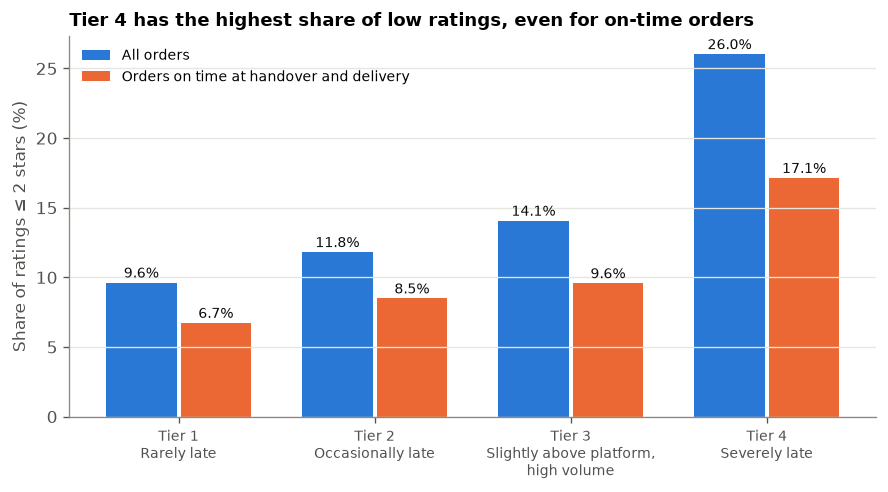

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(1, CHOSEN_K + 1)
width = 0.36
bars_all = ax.bar(x - width / 2 - 0.01, rating_table["low_rating_share"] * 100, width,
                  color="#2a78d6", label="All orders")
bars_ok = ax.bar(x + width / 2 + 0.01, rating_table["low_rating_share_on_time_orders"] * 100, width,
                 color="#eb6834", label="Orders on time at handover and delivery")
for bars in (bars_all, bars_ok):
    for b in bars:
        ax.annotate(f"{b.get_height():.1f}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5, color="#0b0b0b")
ax.set_xticks(x)
tick_labels = [f"Tier {t}\n" + TIER_NAMES.get(t, "").replace(", ", ",\n") for t in x]  # long names on two lines
ax.set_xticklabels(tick_labels, fontsize=8.5)
ax.set_ylabel(f"Share of ratings ≤ {LOW_RATING} stars (%)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("Tier 4 has the highest share of low ratings, even for on-time orders", loc="left")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/q2_03_tier_ratings.png", bbox_inches="tight")
plt.show()

## 6. Focus tiers and the sellers inside them

**Rule:** a tier is a focus tier when its late rate is **above the same-month platform benchmark**
(`gap_vs_same_month_pp > 0`). Focus tiers are ordered by severity, highest first.

Tier 3 is a focus tier mainly because of its many late handovers, not because its sellers are late much
more often than the platform. Because the second feature counts late orders, some large sellers land in
Tier 3 even though their late rate is at or below the platform: their excess late handovers are zero or
negative, so they sit at the bottom of the ranking below. The ranking answers "whom to act on first"; the
tiers answer "which kind of action fits each group".

Inside the focus tiers, sellers are ranked by **excess late handovers** = actual late handovers − the
number expected at the same-month platform rate. It answers: how many late handovers would disappear if
this seller performed like the platform. Whether the top sellers are worse than chance is tested in
`04_checks`.

In [12]:
focus = focus_tiers(profile)
sellers["focus_tier"] = sellers["tier"].isin(focus)
in_focus = sellers[sellers["focus_tier"]]
print(f"Focus tiers (highest priority first): {focus}")
print(f"{len(in_focus)} sellers ({len(in_focus) / len(sellers):.0%} of the {len(sellers)} clustered sellers) account for "
      f"{in_focus['late_orders'].sum() / sellers['late_orders'].sum():.0%} of these sellers' late handovers "
      f"({in_focus['late_orders'].sum() / sellers_all['late_orders'].sum():.0%} of all late handovers in the main sample)")

ranked = in_focus.sort_values("excess_late", ascending=False).reset_index(drop=True)
positive_excess = sellers["excess_late"].clip(lower=0).sum()
print(f"Top 20 sellers cover {ranked['excess_late'].head(20).sum() / positive_excess:.0%} "
      f"of the clustered sellers' excess late handovers")
not_worse = ranked[ranked["excess_late"] <= 0]
print(f"Focus sellers not worse than the same-month platform (excess <= 0): {len(not_worse)}, "
      f"all in tier(s) {', '.join(map(str, sorted(not_worse['tier'].unique())))}, median {not_worse['order_volume'].median():.0f} orders, "
      f"late rate {not_worse['late_orders'].sum() / not_worse['order_volume'].sum():.1%}")
ranked.head(20)[["seller_id", "tier", "order_volume", "late_orders", "late_rate", "excess_late",
                 "avg_review_last"]].style.format({"late_rate": "{:.1%}", "excess_late": "{:.0f}",
                                                   "avg_review_last": "{:.2f}"})

Focus tiers (highest priority first): [4, 3]
159 sellers (20% of the 778 clustered sellers) account for 77% of these sellers' late handovers (64% of all late handovers in the main sample)
Top 20 sellers cover 46% of the clustered sellers' excess late handovers
Focus sellers not worse than the same-month platform (excess <= 0): 20, all in tier(s) 3, median 591 orders, late rate 3.8%


,seller_id,tier,order_volume,late_orders,late_rate,excess_late,avg_review_last
0,7c67e1448b00f6e969d365cea6b010ab,3,963,189,19.6%,134,3.51
1,88460e8ebdecbfecb5f9601833981930,4,224,107,47.8%,94,3.49
2,06a2c3af7b3aee5d69171b0e14f0ee87,4,369,102,27.6%,84,3.99
3,1025f0e2d44d7041d6cf58b6550e0bfa,3,869,115,13.2%,69,4.04
4,8160255418d5aaa7dbdc9f4c64ebda44,3,352,80,22.7%,58,4.02
5,2eb70248d66e0e3ef83659f71b244378,4,185,54,29.2%,45,2.78
6,7aa4334be125fcdd2ba64b3180029f14,4,211,56,26.5%,44,4.14
7,37515688008a7a40ac93e3b2e4ab203f,3,221,53,24.0%,41,4.13
8,a49928bcdf77c55c6d6e05e09a9b4ca5,4,93,41,44.1%,36,3.09
9,1ca7077d890b907f89be8c954a02686a,4,106,37,34.9%,30,2.39


## 7. Save the results

- `seller_tiers.csv`: one row per clustered seller with its tier, excess late handovers and focus flag.
- `focus_sellers_ranked.csv`: sellers in the focus tiers, ranked by excess late handovers.

In [13]:
sellers.to_csv(f"{RESULTS_DIR}/seller_tiers.csv", index=False)
ranked.to_csv(f"{RESULTS_DIR}/focus_sellers_ranked.csv", index=False)
print(f"Saved {len(sellers)} sellers to {RESULTS_DIR}/seller_tiers.csv")
print(f"Saved {len(ranked)} focus-tier sellers to {RESULTS_DIR}/focus_sellers_ranked.csv")

Saved 778 sellers to ../Data/Results/seller_tiers.csv
Saved 159 focus-tier sellers to ../Data/Results/focus_sellers_ranked.csv
